In [1]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-

# Deep Neural Networks 
## Template 02
- multi-class - Fashion MNIST dataset (all 60000 images)

<img src='../../prasami_images/prasami_color_tutorials_small.png' width='400' alt="By Pramod Sharma : pramod.sharma@prasami.com"/>

- one hidden layer
- swish activation f()
- 

In [ ]:
from pathlib import Path  
import numpy as np  #
import pandas as pd  # Import Pandas for data manipulation and analysis with DataFrames
import matplotlib.pyplot as plt  # Import Matplotlib for creating static, interactive visualizations
import seaborn as sns  # Import Seaborn for statistical data visualization built on Matplotlib
from sklearn.model_selection import train_test_split  # Import function to split dataset into training and testing subsets
from sklearn.metrics import accuracy_score, classification_report,f1_score, confusion_matrix, ConfusionMatrixDisplay 
from sklearn.preprocessing import StandardScaler, LabelEncoder
import tensorflow as tf
import torch
import torch.nn as nn
from torchsummary import summary
from torch.utils.data import Dataset, DataLoader


In [3]:
# Some basic parameters
#inpDir = '../../input' 
inpDir = Path('../../input')  # location where input data is stored
outDir = Path('../output')  # location to store outputs
modelDir = Path('../models')  # location of the images
logDir = Path('../logs')
subDir = 'MNIST'

RANDOM_STATE = 24  # for initialization ----- REMEMBER: to remove at the time of promotion
np.random.seed(RANDOM_STATE)  # Set Random Seed for reproducible results
tf.random.set_seed(RANDOM_STATE)  # setting for Tensorflow as well


EPOCHS = 51  # number of epochs
ALPHA = 0.001  # learning rate
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 32 # other sizes leave last batch partial

TRAIN_SIZE = int(BATCH_SIZE * 18)  # to create 64 batches of 256 rows each 0.2
PATIENCE = 20
LR_PATIENCE = 5
LR_FACTOR = 0.1




# Set parameters for decoration of plots
params = {'legend.fontsize' : 'large',
          'figure.figsize'  : (15,15),
          'axes.labelsize'  : 'x-large',
          'axes.titlesize'  :'x-large',
          'xtick.labelsize' :'large',
          'ytick.labelsize' :'large',
         }

plt.rcParams.update(params) # update rcParams
CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid') # plt.style.use('ggplot')

## Load Fashion MNIST dataset

This guide uses the [Fashion MNIST](https://github.com/zalandoresearch/fashion-mnist) dataset which contains 70,000 grayscale images in 10 categories. The images show individual articles of clothing at low resolution (28 by 28 pixels), as seen here:

<table>
  <tr><td>
    <img src="https://tensorflow.org/images/fashion-mnist-sprite.png"
         alt="Fashion MNIST sprite"  width="600">
  </td></tr>
  <tr><td align="center">
    <b>Figure 1.</b> <a href="https://github.com/zalandoresearch/fashion-mnist">Fashion-MNIST samples</a> (by Zalando, MIT License).<br/>&nbsp;
  </td></tr>
</table>

Fashion MNIST is intended as a drop-in replacement for the classic [MNIST](http://yann.lecun.com/exdb/mnist/) dataset—often used as the "Hello, World" of machine learning programs for computer vision. The MNIST dataset contains images of handwritten digits (0, 1, 2, etc.) in a format identical to that of the articles of clothing you'll use here.

This guide uses Fashion MNIST for variety, and because it's a slightly more challenging problem than regular MNIST. Both datasets are relatively small and are used to verify that an algorithm works as expected. They're good starting points to test and debug code.

Here, 60,000 images are used to train the network and 10,000 images to evaluate how accurately the network learned to classify images. You can access the Fashion MNIST directly from TensorFlow. Import and [load the Fashion MNIST data](https://www.tensorflow.org/api_docs/python/tf/keras/datasets/fashion_mnist/load_data) directly from TensorFlow:

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'Using {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'cpu'}')

(modelDir / subDir).mkdir(parents=True, exist_ok=True)

Using cpu


In [5]:
train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')

<table>
  <tr>
    <th>Label</th>
    <th>Class</th>
  </tr>
  <tr>
    <td>0</td>
    <td>T-shirt/top</td>
  </tr>
  <tr>
    <td>1</td>
    <td>Trouser</td>
  </tr>
    <tr>
    <td>2</td>
    <td>Pullover</td>
  </tr>
    <tr>
    <td>3</td>
    <td>Dress</td>
  </tr>
    <tr>
    <td>4</td>
    <td>Coat</td>
  </tr>
    <tr>
    <td>5</td>
    <td>Sandal</td>
  </tr>
    <tr>
    <td>6</td>
    <td>Shirt</td>
  </tr>
    <tr>
    <td>7</td>
    <td>Sneaker</td>
  </tr>
    <tr>
    <td>8</td>
    <td>Bag</td>
  </tr>
    <tr>
    <td>9</td>
    <td>Ankle boot</td>
  </tr>
</table>

Each image is mapped to a single label. Since the *class names* are not included with the dataset, store them here to use later when plotting the images:

In [6]:
#class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
#               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

class_names = {0: 'T-shirt/top',1:'Trouser',2:'Pullover',3:'Dress',4:'Coat',
               5:'Sandal', 6: 'Shirt',7: 'Sneaker', 8:'Bag', 9: 'Ankle boot'}

## Explore the data

Let's explore the format of the dataset before training the model. The following shows there are 60,000 images in the training set, with each image represented as 28 x 28 pixels:

In [7]:
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
train_df.shape, test_df.shape

((60000, 785), (10000, 785))

Each label is an integer between 0 and 9:

In [9]:
train_df['label'].unique()

array([2, 9, 6, 0, 3, 4, 5, 8, 7, 1])

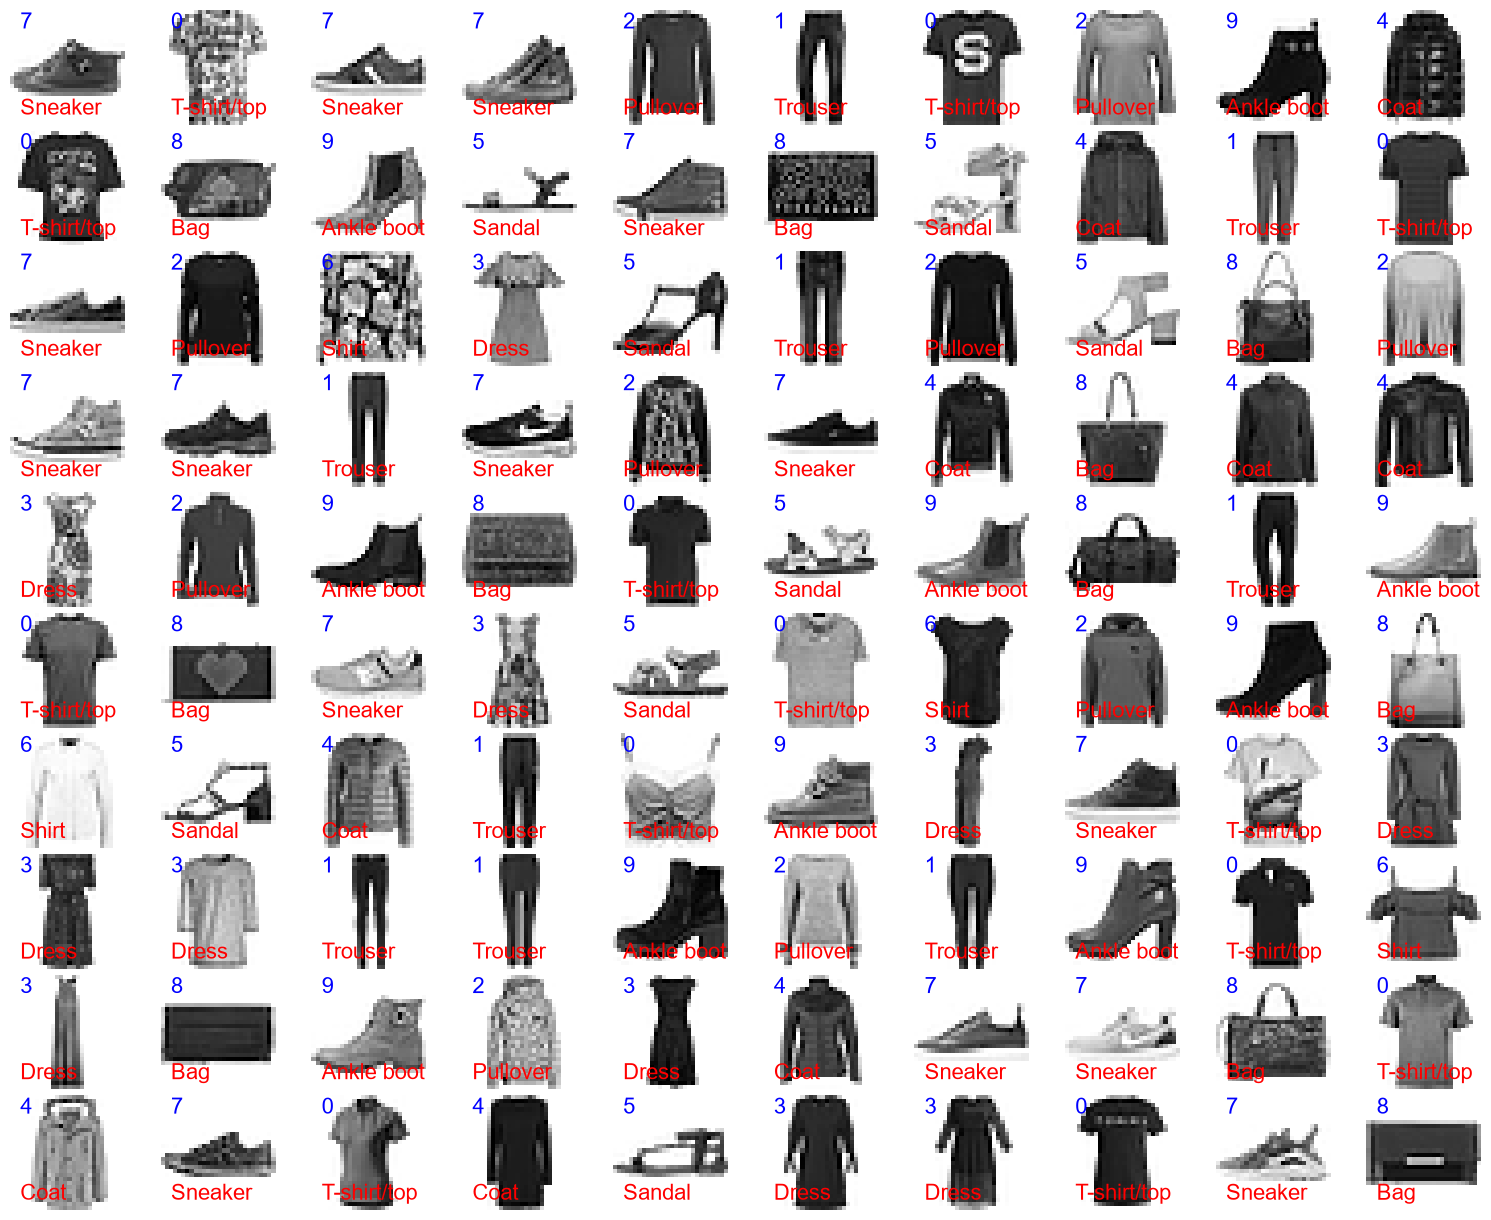

In [10]:
# Sample data plot

plot_df = train_df.sample(n = 100) # Take 100 sample from the training set

fig = plt.figure(figsize=(15, 12))  # figure size in inches

fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.05, wspace=0.05) # adjust subplots

i = 0

for _ , row in plot_df.iterrows(): # iterate through all rows of the dataframe
    
    i = i + 1
    
    image = row.values[1:].reshape(28,28) # reshape row to a 28x28 matrix
    
    ax = fig.add_subplot(10, 10, (i), xticks=[], yticks=[]) # add a subplot to the figure
    
    ax.imshow(image, cmap=plt.cm.binary, interpolation='nearest') # show image on the axis
    
    ax.text(2, 4, str(row.iloc[0]), color='b', fontsize=16)   # add number (class) of the image
    
    ax.text(2, 25, class_names[row.iloc[0]], color='r', fontsize=16)   # add name of the image
    
plt.show()

In [11]:
# sc = StandardScaler()
# X_train = sc.fit_transform(X_train)
# X_test = sc.transform(X_test)

# Transoformer Class

In [12]:
class DataTransformer:
    
    def __init__(self):
        self.scaler = StandardScaler()
        self.encoder = LabelEncoder()
        self.is_fitted = False

    def fit(self, X, y):
        self.scaler.fit(X)
        self.encoder.fit(y)
        self.is_fitted = True
        return self

    def transform(self, X, y):
        if not self.is_fitted:
            raise ValueError("Transformera must be fitted first")
        return self.scaler.transform(X), self.encoder.transform(y)

    def fit_transform(self, X, y):
        self.fit(X, y)
        return self.transform(X, y)
        

# Define Dataset

In [13]:
class MnistDS(Dataset):
    
    def __init__(self,
                 dataframe: pd.DataFrame,
                 is_train = True,
                 label_col = None,
                 transformer = None):
        
        super(MnistDS, self).__init__()
        
        self.df = dataframe
        self.is_train = is_train
        self.label_col = label_col
        self.transformer = transformer
        
        y = self.df[self.label_col].to_numpy()
        X = self.df.drop(label_col, axis=1)        

        if self.is_train:
            self.transformer = DataTransformer()
            self.features, self.labels = self.transformer.fit_transform(X, y)

        else:
            if self.transformer is None:
                raise ValueError('Test set requires pre-fitted transformer')
            self.features, self.labels = self.transformer.transform(X, y)
                
    def __len__(self):
        return len(self.features)
        
    def __getitem__(self, index):
        feature = self.features[index]
        label = self.labels[index]
        feature = torch.tensor(feature, dtype=torch.float32)
        label = torch.tensor(label, dtype=torch.int64)

        return feature, label

In [14]:
label_col = 'label'
train_dataset = MnistDS(train_df, is_train=True, label_col=label_col)
train_loader = DataLoader(
    dataset=train_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True)

In [15]:
label_col = 'label'
test_dataset = MnistDS(test_df, is_train=False, label_col=label_col, transformer=train_dataset.transformer)
test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [16]:
class Model(nn.Module):
    def __init__(self, input_dim):
        super(Model,self).__init__()

        dor1 = 0.10
        dor2 = 0.20
        dor3 = 0.30
        
        self.layer1 = nn.Linear(input_dim, 784)
        self.bn1 = nn.BatchNorm1d(784)
        self.activ1 = nn.SiLU()
        self.do1 = nn.Dropout(dor1)
        
        self.layer2 = nn.Linear(784, 196)
        self.bn2 = nn.BatchNorm1d(196)
        self.activ2 = nn.SiLU()
        self.do2 = nn.Dropout(dor2)

        self.layer3 = nn.Linear(196, 49)
        self.bn3 = nn.BatchNorm1d(49)
        self.activ3 = nn.SiLU()
        self.do3 = nn.Dropout(dor3)

        self.layer4 = nn.Linear(49,10)
       

    def forward(self, x):
        x = self.do1(self.activ1(self.bn1(self.layer1(x))))
        x = self.do2(self.activ2(self.bn2(self.layer2(x))))
        x = self.do3(self.activ3(self.bn3(self.layer3(x))))
        
        return x

## Whats in the data?

## Preprocess the data

The data must be preprocessed before training the network. If you inspect the first image in the training set, you will see that the pixel values fall in the range of 0 to 255:

Scale these values to a range of 0 to 1 before feeding them to the neural network model. To do so, divide the values by 255. It's important that the *training set* and the *testing set* be preprocessed in the same way:

In [17]:
input_dim = 784
model = Model(input_dim=input_dim).to(device=device)
model

Model(
  (layer1): Linear(in_features=784, out_features=784, bias=True)
  (bn1): BatchNorm1d(784, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activ1): SiLU()
  (do1): Dropout(p=0.1, inplace=False)
  (layer2): Linear(in_features=784, out_features=196, bias=True)
  (bn2): BatchNorm1d(196, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activ2): SiLU()
  (do2): Dropout(p=0.2, inplace=False)
  (layer3): Linear(in_features=196, out_features=49, bias=True)
  (bn3): BatchNorm1d(49, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (activ3): SiLU()
  (do3): Dropout(p=0.3, inplace=False)
  (layer4): Linear(in_features=49, out_features=10, bias=True)
)

In [18]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),
                             lr=ALPHA,
                             weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer=optimizer,
                                                      mode='min',
                                                      factor=LR_FACTOR,
                                                      patience=LR_PATIENCE,
                                                      min_lr=1e-6)

train_losses, test_losses, train_accuracy, test_accuracy, n_epoch = [], [], [], [], []

minLoss = float('inf') # criteria for saving the model
counter = 0 # compared against the patience
savePath = modelDir/subDir/'mnist.pth'

In [19]:
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    test_loss = 0
    train_acc = 0
    test_acc = 0
    
    for batch_idx, (train_X, train_y) in enumerate(train_loader):
    
        train_X, train_y = train_X.to(device), train_y.to(device)
        predict_prob = model(train_X) # Forward propagation
        batch_loss = loss_fn(predict_prob, train_y) # calculate loss
        train_loss += (batch_loss - train_loss) / (batch_idx+1)
    
        # Back propagation
        optimizer.zero_grad() # reset
        batch_loss.backward() # back Prop (dWs dbs)
        optimizer.step() # W = W + alpha * dW
    
        _, y_pred = torch.max(predict_prob, 1)
        batch_acc = accuracy_score(train_y.cpu().numpy(), y_pred.data.cpu())
        train_acc += (batch_acc - train_acc) / (batch_idx+1)

    train_losses.append(train_loss.item())
    train_accuracy.append(train_acc)

    model.eval()
    with torch.inference_mode():
            for batch_idx, (test_X, test_y) in enumerate(test_loader):
                test_X, test_y = test_X.to(device), test_y.to(device)
                predict_prob_tst = model(test_X) # Forward propagation
                tbatch_loss = loss_fn(predict_prob_tst, test_y) # calculate loss
                test_loss += (tbatch_loss - test_loss) / (batch_idx+1)
                
                _, y_pred = torch.max(predict_prob_tst, 1)
                tbatch_acc = accuracy_score(test_y.cpu().numpy(), y_pred.data.cpu())
                test_acc += (tbatch_acc - test_acc) / (batch_idx+1)
                
            test_losses.append(test_loss.item())
            test_accuracy.append(test_acc)
        
    n_epoch.append(epoch)

    scheduler.step(test_loss)

    ## Add for early stopping

    if test_loss < minLoss:
        minLoss = test_loss
        counter = 0
        torch.save({'epoch' : epoch+1, 
                    'model_state_dict' : model.state_dict(),
                    'Optimizer_state_dict' : optimizer.state_dict(),
                    'Loss' : test_loss}, savePath)
    else:
        counter += 1

    if counter > PATIENCE:
            break
        
    if epoch % 10 == 0:
      print(f' At epoch - {epoch:4d} :'
            f' Train loss- {train_loss.item():.4f}'
            f' Test Loss - {test_loss.item():.4f}'
            f' Train acc - {train_acc:.4f}'
            f' Test acc - {test_acc:.4f}')
    

 At epoch -    0 : Train loss- 1.8363 Test Loss - 0.8737 Train acc - 0.5867 Test acc - 0.8465
 At epoch -   10 : Train loss- 1.4747 Test Loss - 0.6088 Train acc - 0.6405 Test acc - 0.8842
 At epoch -   20 : Train loss- 1.4386 Test Loss - 0.5670 Train acc - 0.6482 Test acc - 0.8943
 At epoch -   30 : Train loss- 1.3751 Test Loss - 0.4982 Train acc - 0.6638 Test acc - 0.9019
 At epoch -   40 : Train loss- 1.3585 Test Loss - 0.4985 Train acc - 0.6682 Test acc - 0.9044
 At epoch -   50 : Train loss- 1.3502 Test Loss - 0.4769 Train acc - 0.6705 Test acc - 0.9015


In [35]:
loss_df = pd.DataFrame({
    'epoch': n_epoch, 
    'loss': train_losses, 
    'test_loss': test_losses,
    'acc': train_accuracy, 
    'test_acc': test_accuracy
})

In [36]:
def fn_plot_tf_hist(hist_df):

    '''
    Args:
        hist_df: a DataFrame with column names accuracy,loss	val_accuracy	val_loss
    '''

    fig, axes = plt.subplots(1,2 , figsize = (15,6))

    # properties  matplotlib.patch.Patch
    props = dict(boxstyle='round', facecolor='aqua', alpha=0.4)
    facecolor = 'cyan'
    fontsize=12
    CMAP = plt.cm.coolwarm

    # Get columns by index to eliminate any column naming error
    y1 = hist_df.columns[0]
    y2 = hist_df.columns[1]
    y3 = hist_df.columns[2]
    y4 = hist_df.columns[3]

    # Where was min loss
    best = hist_df[hist_df[y4] == hist_df[y4].min()]

    ax = axes[0]

    hist_df.plot(y = [y2,y4], ax = ax, colormap=CMAP)


    # little beautification
    txtFmt = "Loss: \n  train: {:6.4f}\n   test: {:6.4f}"
    txtstr = txtFmt.format(hist_df.iloc[-1][y2],
                           hist_df.iloc[-1][y4]) #text to plot

    # place a text box in upper middle in axes coords
    ax.text(0.3, 0.95, txtstr, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)

    # calculate offset for arrow
    y_min = min(hist_df[y2].min(), hist_df[y4].min())
    y_max = max(hist_df[y2].max(), hist_df[y4].max())
    offset = (y_max-y_min)/10.0

    best_idx = best.index.to_numpy()[0]  # Extract first (and only) element as scalar
    best_value = best[y4].to_numpy()[0]   # Extract scalar value

    # Mark arrow at lowest
    ax.annotate(f'Min: {best_value:6.4f}', # text to print
                xy=(best_idx, best_value), # Arrow start
                xytext=(best_idx, best_value + offset), # location of text
                fontsize=fontsize, va='bottom', ha='right',bbox=props, # beautification of text
                arrowprops=dict(facecolor=facecolor, shrink=0.05)) # arrow

    ax.axvline(x = best_idx, color = 'green', linestyle='-.', lw = 3)

    ax.set_xlabel("Epochs")
    ax.set_ylabel(y2.capitalize())
    ax.set_title('Loss Curve')
    ax.grid(True)
    ax.legend(loc = 'upper left') # model legend to upper left

    ax = axes[1]

    hist_df.plot( y = [y1, y3], ax = ax, colormap=CMAP)

    # little beautification
    txtFmt = "Accuracy: \n  train: {:6.4f}\n  test:  {:6.4f}"
    txtstr = txtFmt.format(hist_df.iloc[-1][y1],
                           hist_df.iloc[-1][y3]) #text to plot

    # place a text box in upper middle in axes coords
    ax.text(0.3, 0.2, txtstr, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)

    # calculate offset for arroe
    y_min = min(hist_df[y1].min(), hist_df[y3].min())
    y_max = max(hist_df[y1].max(), hist_df[y3].max())
    offset = (y_max-y_min)/10.0

    best_value = best[y3].to_numpy()[0]   # Extract scalar value
    # Mark arrow at lowest
    ax.annotate(f'Best: {best_value:6.4f}', # text to print
                xy=(best_idx, best_value), # Arrow start
                xytext=(best_idx, best_value-offset), # location of text
                fontsize=fontsize, va='bottom', ha='right',bbox=props, # beautification of text
                arrowprops=dict(facecolor=facecolor, shrink=0.05)) # arrow


    # Draw vertical line at best value
    ax.axvline(x = best_idx, color = 'green', linestyle='-.', lw = 3)

    ax.set_xlabel("Epochs")
    ax.set_ylabel(y1.capitalize())
    ax.set_title('Accuracy Curve')
    ax.grid(True)
    ax.legend(loc = 'lower left')

    plt.tight_layout()





###----------------------------------------------------
### Plot number of classes in training and testing sets
###----------------------------------------------------
def fn_plot_label(tr_ds, ts_ds, class_names = None):

    '''
        Args:
            tr_ds :  Training Dataset
            ts_ds : Testing dataset
            class_names : Class names
        Returns : none
    '''

    # create figure and axes
    fig, axes = plt.subplots(1,2, figsize = (15,5))

    # get names of the classes
    if not class_names:
        tr_class_names = tr_ds.class_names
        ts_class_names = tr_ds.class_names

    # pick first axis
    ax = axes[0]

    # create dict of training labels
    class_counts = {}
    for imgs, lbls in tr_ds:
        for lbl in lbls.numpy():
            class_counts[lbl] = class_counts.get(lbl, 0) +1

    # bar plot
    ax.bar(tr_class_names, [class_counts.get(i, 0) for i in range(len(tr_class_names))],
           align='center',color = 'DarkBlue', alpha = 0.7)

    # add title
    ax.set_title('Training Set')

    # grids make it look good
    ax.grid(True)


    #pick second image
    ax = axes[1]

    # create dict of training labels
    class_counts = {}
    for imgs, lbls in ts_ds:
        for lbl in lbls.numpy():
            class_counts[lbl] = class_counts.get(lbl, 0) +1

    # bar plot
    ax.bar(ts_class_names, [class_counts.get(i, 0) for i in range(len(ts_class_names))],
           align='center',color = 'orange', alpha = 0.7)

    # add title
    ax.set_title('Test Set')


    # grids make it look good
    ax.grid(True)

    # fit the subplot(s) in to the figure area
    plt.tight_layout()

    # display all open figures
    plt.show()

###-------------------------------
### Convert datetime from a string
###-------------------------------
def fn_convert_timestamp(tstr):
    '''
        Function to conver string of form "2015-11-12 1444"
    '''

    return datetime.strptime(tstr, "%Y-%m-%d_%H%M")

###----------------------
### Plot confusion matrix
###----------------------
def fn_plot_confusion_matrix(y_true, y_pred, labels):
    '''
    Args:
        y_true: Ground Truth
        y_pred : Predictions
        labels : labels in a dictonary
               e.g.{0: 'Goal Keeper',
                  1: 'Defender',
                  2: 'Mid-Fielder',
                  3: 'Forward'}

    '''

    cm  = confusion_matrix(y_true, y_pred)

    if isinstance(labels, dict):
        display_labels = labels.values()
    else:
        display_labels = labels

    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=display_labels)

    fig, ax = plt.subplots(figsize = (5,5))

    disp.plot(ax = ax, cmap = 'Blues', xticks_rotation = 'vertical', colorbar=False)

    # Disable the grid
    ax.grid(False)

    title_str = f'F1 Score : {f1_score(y_true, y_pred, average='weighted'):0.5f}'
    ax.set_title(title_str)

    plt.show()



def fn_plot_torch_hist(hist_df: pd.DataFrame):
    """
    Plots the training and validation loss and accuracy curves from a PyTorch training history DataFrame.

    Args:
        hist_df (pd.DataFrame): A pandas DataFrame with five columns:
                                - First column: epoch (x-axis values)
                                - Second & third columns: losses (train & validation)
                                - Fourth & fifth columns: accuracies (train & validation)

    Returns:
        None: Displays the matplotlib plots.
    """
    # Ensure the DataFrame ha****actly five columns
    if hist_df.shape[1] < 5:
        raise ValueError("The DataFrame must have atleast five columns: epoch, train_loss, val_loss, train_acc, val_acc.")

    # Extract column names for better readability and maintainability
    #epoch loss	           test_loss	 acc	        test_acc
    x_col, train_loss_col, val_loss_col, train_acc_col, val_acc_col, *cols= hist_df.columns

    # Instantiate figure with two subplots
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    facecolor = 'cyan'  # Text box background color
    fontsize = 12  # Font size for annotations
    props = dict(boxstyle='round', facecolor=facecolor, alpha=0.5)  # Text box properties

    # First subplot: Loss curves
    ax = axes[0]
    hist_df.plot(x=x_col, y=[train_loss_col, val_loss_col], ax=ax)

    # Annotation: Final losses
    final_losses_text = f"Loss:\nTrain: {hist_df[train_loss_col].iloc[-1]:.4f}\nTest:  {hist_df[val_loss_col].iloc[-1]:.4f}"
    ax.text(0.3, 0.95, final_losses_text, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)

    # Annotation: Minimum validation loss
    best_val_loss_idx = hist_df[val_loss_col].idxmin()
    best_val_loss_epoch = hist_df.loc[best_val_loss_idx, x_col]
    best_val_loss_value = hist_df.loc[best_val_loss_idx, val_loss_col]
    best_val_acc_value = hist_df.loc[best_val_loss_idx, val_acc_col]

    # calculate offset for arrow
    y_min = min(hist_df[train_loss_col].min(), hist_df[val_loss_col].min())
    y_max = max(hist_df[train_loss_col].max(), hist_df[val_loss_col].max())
    offset = (y_max-y_min)/10.0

    ax.annotate(f"Min: {best_val_loss_value:.4f}",
                xy=(best_val_loss_epoch, best_val_loss_value),
                xytext=(best_val_loss_epoch, best_val_loss_value + offset),
                fontsize=fontsize, ha='right', va='bottom', bbox=props,
                arrowprops=dict(facecolor=facecolor, shrink=0.05))
    ax.axvline(x=best_val_loss_epoch, color='green', linestyle='-.', lw=2)

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title("Loss Curves")
    ax.legend(loc='upper left')
    ax.grid(True)

    # Second subplot: Accuracy curves
    ax = axes[1]
    hist_df.plot(x=x_col, y=[train_acc_col, val_acc_col], ax=ax)

    # Annotation: Final accuracies
    final_acc_text = f"Accuracy:\nTrain: {hist_df[train_acc_col].iloc[-1]:.4f}\nTest:  {hist_df[val_acc_col].iloc[-1]:.4f}"
    ax.text(0.3, 0.2, final_acc_text, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)

    # calculate offset for arrow
    y_min = min(hist_df[train_acc_col].min(), hist_df[train_acc_col].min())
    y_max = max(hist_df[train_acc_col].max(), hist_df[train_acc_col].max())
    offset = (y_max-y_min)/10.0

    ax.annotate(f"Best: {best_val_acc_value:.4f}",
                xy=(best_val_loss_idx, best_val_acc_value),
                xytext=(best_val_loss_idx, best_val_acc_value - offset),
                fontsize=fontsize, ha='right', va='top', bbox=props,
                arrowprops=dict(facecolor=facecolor, shrink=0.05))
    ax.axvline(x=best_val_loss_epoch, color='green', linestyle='-.', lw=2)

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.set_title("Accuracy Curves")
    ax.legend(loc='lower left')
    ax.grid(True)

    plt.tight_layout()
    plt.show()

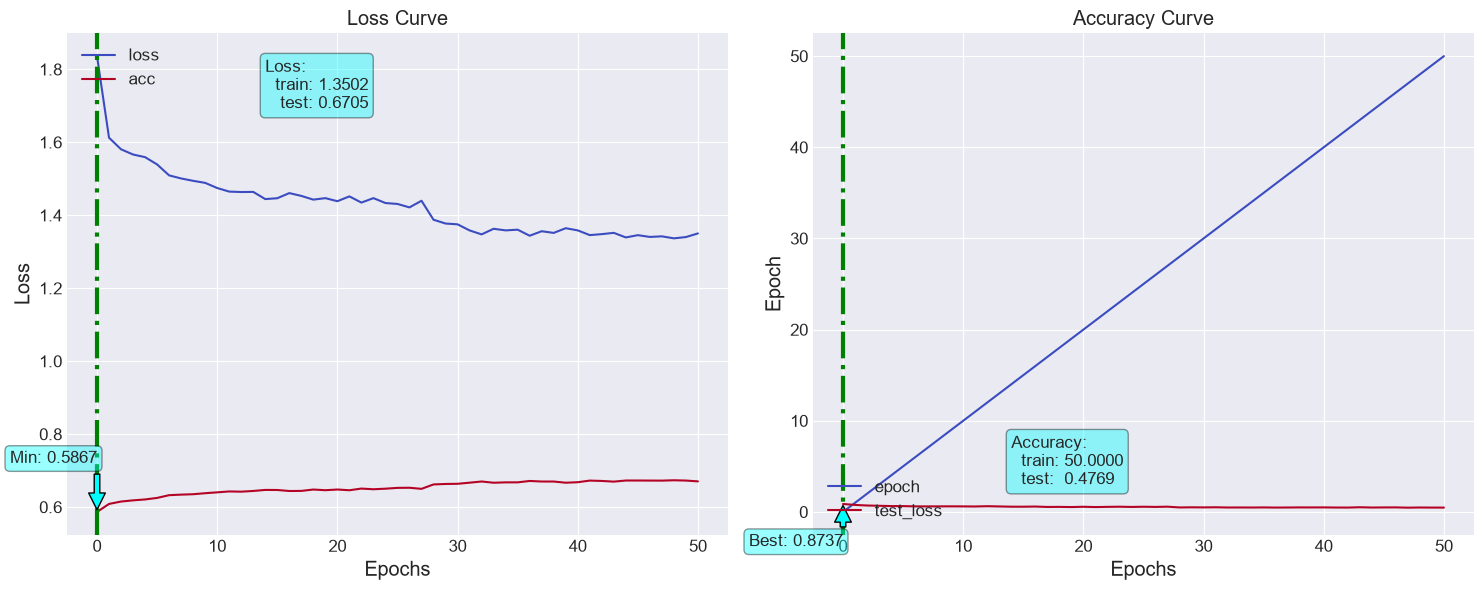

In [37]:
fn_plot_tf_hist(loss_df)

In [38]:
y_train, y_pred = [], []
model.eval()
with torch.inference_mode():
    for batch_idx, (train_X, train_y) in enumerate(train_loader):
        train_X, train_y = train_X.to(device), train_y.to(device)
        predict_prob_tst = model(train_X)  # Forward propagation
        preds = torch.argmax(predict_prob_tst, dim=1)
        y_pred.extend(preds.cpu().numpy())
        y_train.extend(train_y.cpu().numpy())

print(f'Train Acc: {accuracy_score(y_train, y_pred):.5f}')
classification_report(y_train, y_pred)


Train Acc: 0.95132


'              precision    recall  f1-score   support\n\n           0       0.91      0.92      0.91      6000\n           1       1.00      1.00      1.00      6000\n           2       0.93      0.90      0.91      6000\n           3       0.95      0.96      0.95      6000\n           4       0.91      0.90      0.91      6000\n           5       1.00      1.00      1.00      6000\n           6       0.86      0.88      0.87      6000\n           7       0.98      0.99      0.99      6000\n           8       1.00      0.99      0.99      6000\n           9       0.99      0.98      0.99      6000\n\n    accuracy                           0.95     60000\n   macro avg       0.95      0.95      0.95     60000\nweighted avg       0.95      0.95      0.95     60000\n'

In [39]:
class_names = {k:v for k,v in enumerate(train_dataset.transformer.encoder.classes_)}

NameError: name 'f1_score' is not defined

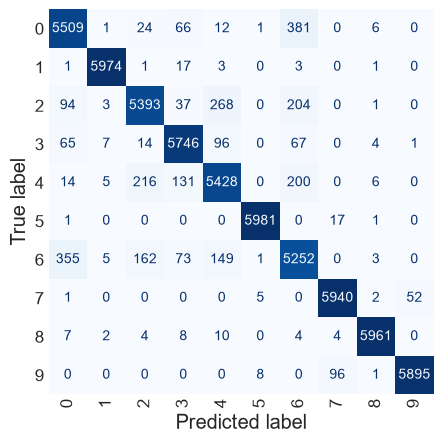

In [41]:
fn_plot_confusion_matrix(y_train, y_pred, labels=list(class_names.values()))